In [5]:
%pip install kagglehub pandas numpy matplotlib scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.


In [7]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt

# Machine learning
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_squared_log_error
)

# Dataset acquisition
import kagglehub

# File management
from pathlib import Path
import joblib

# Other utilities
import warnings

warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [11]:
from pathlib import Path
import shutil

src = Path.home() / "Downloads" / "kaggle.json"
dst = Path.home() / ".kaggle" / "kaggle.json"
dst.parent.mkdir(exist_ok=True)
if src.exists():
    shutil.copy(src, dst)
    print("Copied to {dst}")
else:
    print("Kaggle.json not found in Downloads")

Copied to {dst}


In [46]:
# Download Kaggle competition dataset
data_path = kagglehub.competition_download(
    "store-sales-time-series-forecasting"
)

data_path = Path(data_path)

print("Dataset downloaded successfully!")
print("Dataset location:", data_path)

Dataset downloaded successfully!
Dataset location: C:\Users\jabul\.cache\kagglehub\competitions\store-sales-time-series-forecasting


In [47]:
for file in data_path.rglob("*"):
    if file.is_file():
        print(file.name)

holidays_events.csv
oil.csv
sample_submission.csv
stores.csv
test.csv
train.csv
transactions.csv


In [48]:
# Load the main training dataset
df = pd.read_csv(
    data_path / "train.csv",
    parse_dates=["date"]
)

# Load supporting datasets
stores = pd.read_csv(data_path / "stores.csv")
oil = pd.read_csv(
    data_path / "oil.csv",
    parse_dates=["date"]
)
holidays = pd.read_csv(
    data_path / "holidays_events.csv",
    parse_dates=["date"]
)
transactions = pd.read_csv(
    data_path / "transactions.csv",
    parse_dates=["date"]
)

print("All datasets loaded successfully!")

print("\nTraining dataset:")
display(df.head())

print("\nStores dataset:")
display(stores.head())

print("\nOil dataset:")
display(oil.head())

print("\nHoliday dataset:")
display(holidays.head())

print("\nTransactions dataset:")
display(transactions.head())

All datasets loaded successfully!

Training dataset:


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0



Stores dataset:


,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8
3,4,Quito,Pichincha,D,9
4,5,Santo Domingo,Santo Domingo de los Tsachilas,D,4



Oil dataset:


,date,dcoilwtico
0,2013-01-01,NaN
1,2013-01-02,93.14
2,2013-01-03,92.97
3,2013-01-04,93.12
4,2013-01-07,93.20



Holiday dataset:


,date,type,locale,locale_name,description,transferred
0,2012-03-02,Holiday,Local,Manta,Fundacion de Manta,False
1,2012-04-01,Holiday,Regional,Cotopaxi,Provincializacion de Cotopaxi,False
2,2012-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,False
3,2012-04-14,Holiday,Local,Libertad,Cantonizacion de Libertad,False
4,2012-04-21,Holiday,Local,Riobamba,Cantonizacion de Riobamba,False



Transactions dataset:


,date,store_nbr,transactions
0,2013-01-01,25,770
1,2013-01-02,1,2111
2,2013-01-02,2,2358
3,2013-01-02,3,3487
4,2013-01-02,4,1922


In [49]:
# Dataset dimensions
print("Dataset shape:", df.shape)

# Column information
df.info()

# Statistical summary
display(df.describe())

# Unique stores
print("Number of stores:", df["store_nbr"].nunique())

# Unique product families
print("Product families:", df["family"].nunique())

# Date range
print("Start date:", df["date"].min())
print("End date:", df["date"].max())

# Total sales
print("Total historical sales:", df["sales"].sum())

Dataset shape: (3000888, 6)
<class 'pandas.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype         
---  ------       -----         
 0   id           int64         
 1   date         datetime64[us]
 2   store_nbr    int64         
 3   family       str           
 4   sales        float64       
 5   onpromotion  int64         
dtypes: datetime64[us](1), float64(1), int64(3), str(1)
memory usage: 168.2 MB


,id,date,store_nbr,sales,onpromotion
count,3.000888e+06,3000888,3.000888e+06,3.000888e+06,3.000888e+06
mean,1.500444e+06,2015-04-24 08:27:04.703088,2.750000e+01,3.577757e+02,2.602770e+00
min,0.000000e+00,2013-01-01 00:00:00,1.000000e+00,0.000000e+00,0.000000e+00
25%,7.502218e+05,2014-02-26 18:00:00,1.400000e+01,0.000000e+00,0.000000e+00
50%,1.500444e+06,2015-04-24 12:00:00,2.750000e+01,1.100000e+01,0.000000e+00
75%,2.250665e+06,2016-06-19 06:00:00,4.100000e+01,1.958473e+02,0.000000e+00
max,3.000887e+06,2017-08-15 00:00:00,5.400000e+01,1.247170e+05,7.410000e+02
std,8.662819e+05,NaN,1.558579e+01,1.101998e+03,1.221888e+01


Number of stores: 54
Product families: 33
Start date: 2013-01-01 00:00:00
End date: 2017-08-15 00:00:00
Total historical sales: 1073644952.2030684


In [50]:
# Missing values
missing_values = df.isnull().sum()

print("Missing values:")
display(missing_values)

# Duplicate records
print("Duplicate records:", df.duplicated().sum())

# Negative sales
print("Negative sales records:", (df["sales"] < 0).sum())

# Zero sales
print("Zero sales records:", (df["sales"] == 0).sum())

Missing values:


id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64

Duplicate records: 0
Negative sales records: 0
Zero sales records: 939130


In [16]:
daily_sales = (
    df.groupby("date", as_index=False)["sales"]
    .sum()
    .sort_values("date")
)

daily_sales.rename(
    columns={"sales": "total_sales"},
    inplace=True
)

display(daily_sales.head())

print("Daily dataset shape:", daily_sales.shape)

,date,total_sales
0,2013-01-01,2511.618999
1,2013-01-02,496092.417944
2,2013-01-03,361461.231124
3,2013-01-04,354459.677093
4,2013-01-05,477350.121229


Daily dataset shape: (1684, 2)


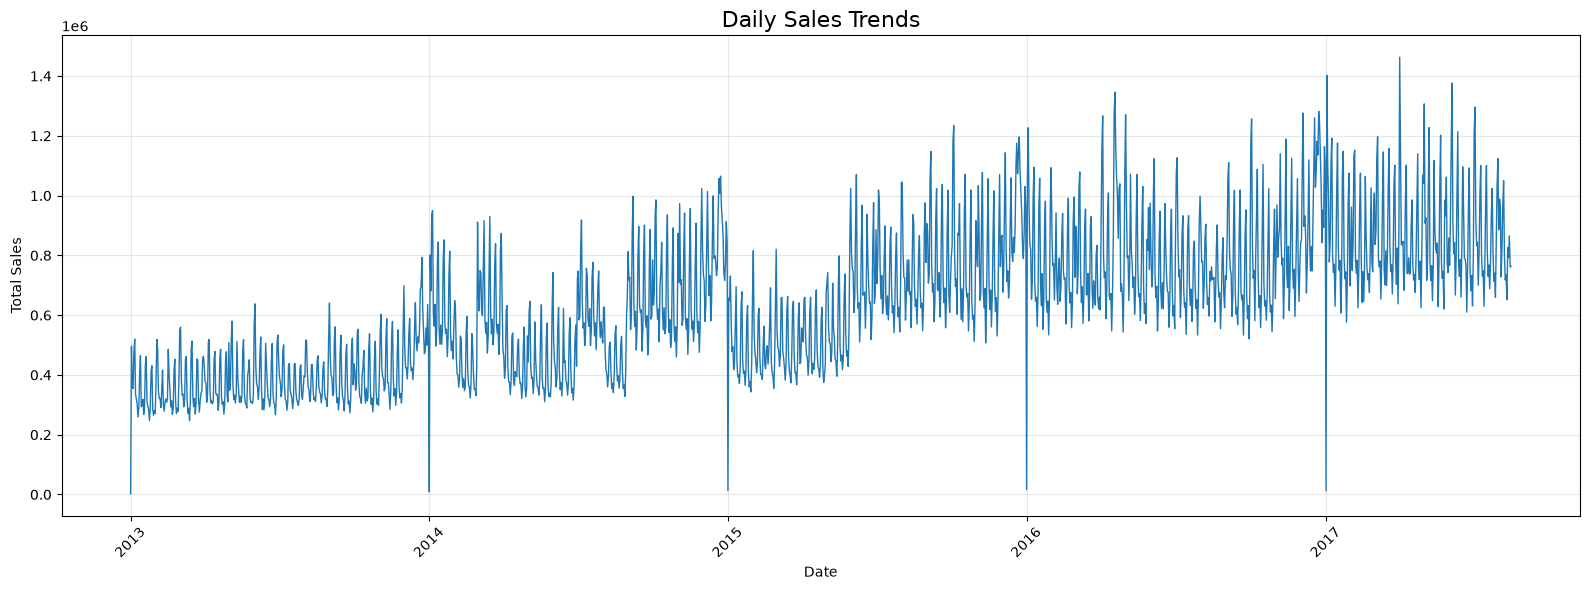

In [17]:
plt.figure(figsize=(16, 6))

plt.plot(
    daily_sales["date"],
    daily_sales["total_sales"],
    linewidth=1
)

plt.title("Daily Sales Trends", fontsize=16)
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.grid(alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "daily_sales_trend.png")
plt.show()

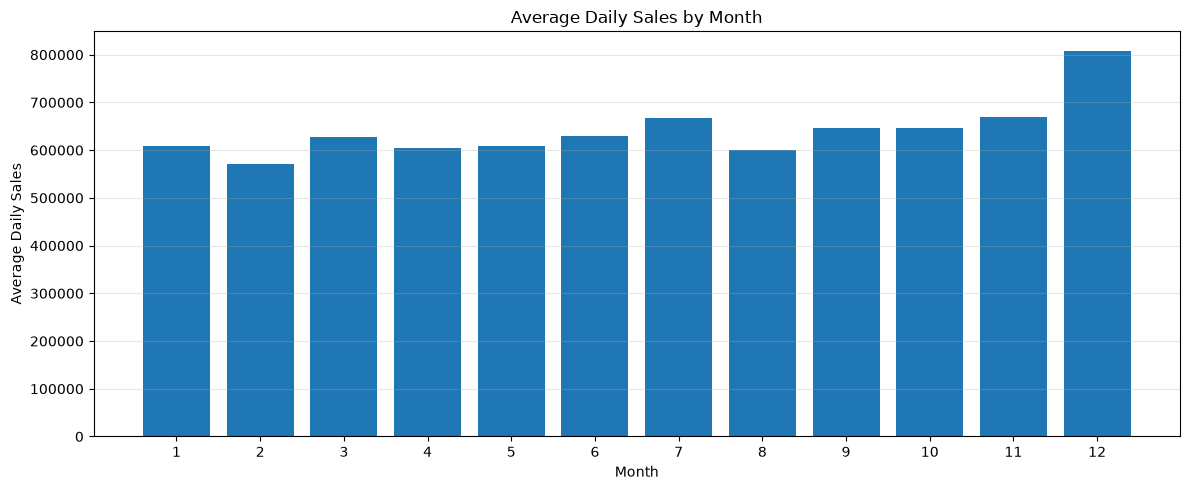

In [18]:
daily_sales["month"] = daily_sales["date"].dt.month

monthly_sales = (
    daily_sales.groupby("month")["total_sales"]
    .mean()
)

plt.figure(figsize=(12, 5))

plt.bar(
    monthly_sales.index,
    monthly_sales.values
)

plt.title("Average Daily Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Daily Sales")
plt.xticks(range(1, 13))
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "monthly_sales.png")
plt.show()

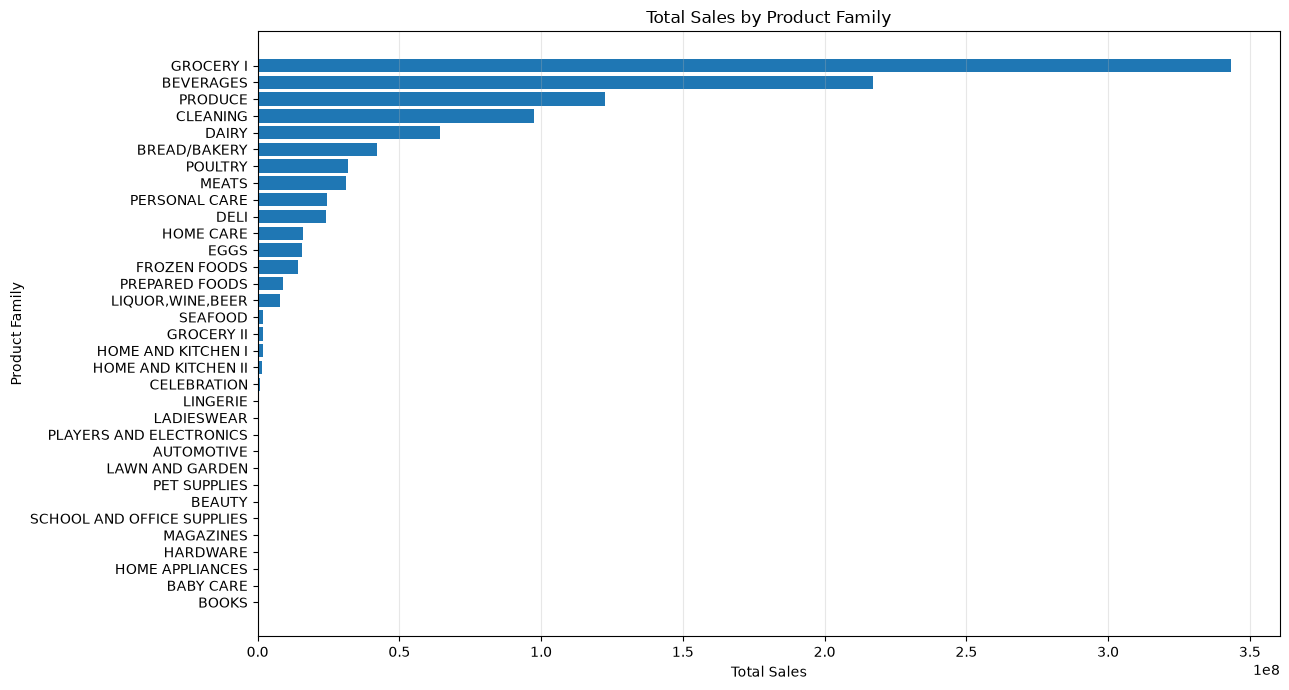

In [19]:
family_sales = (
    df.groupby("family")["sales"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(13, 7))

plt.barh(
    family_sales.index,
    family_sales.values
)

plt.title("Total Sales by Product Family")
plt.xlabel("Total Sales")
plt.ylabel("Product Family")
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "family_sales.png")
plt.show()

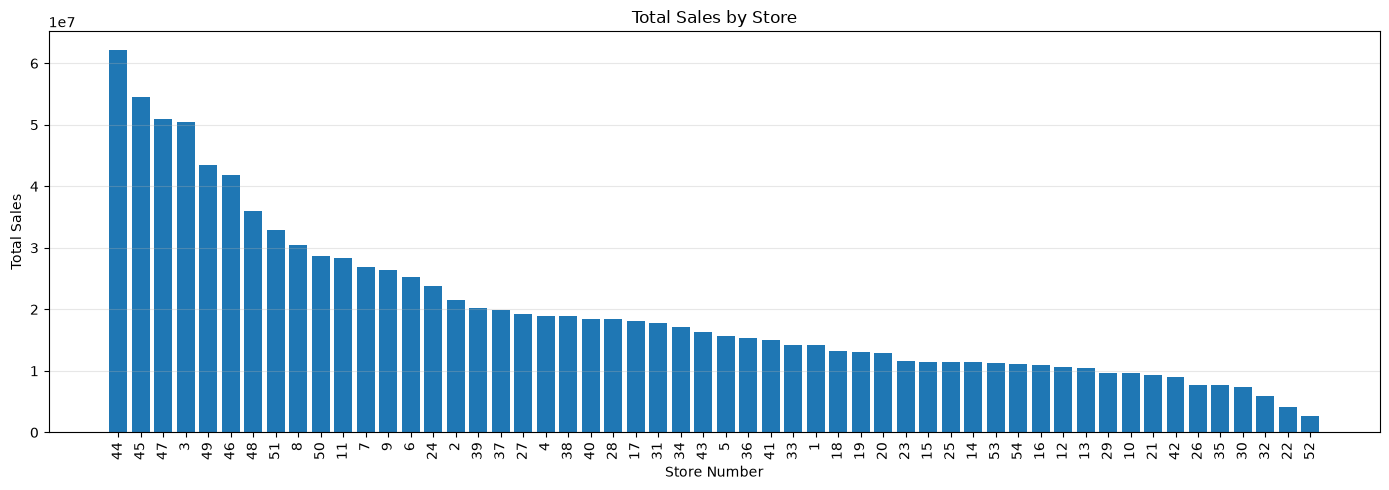

In [20]:
store_sales = (
    df.groupby("store_nbr")["sales"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(14, 5))

plt.bar(
    store_sales.index.astype(str),
    store_sales.values
)

plt.title("Total Sales by Store")
plt.xlabel("Store Number")
plt.ylabel("Total Sales")
plt.xticks(rotation=90)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "store_sales.png")
plt.show()

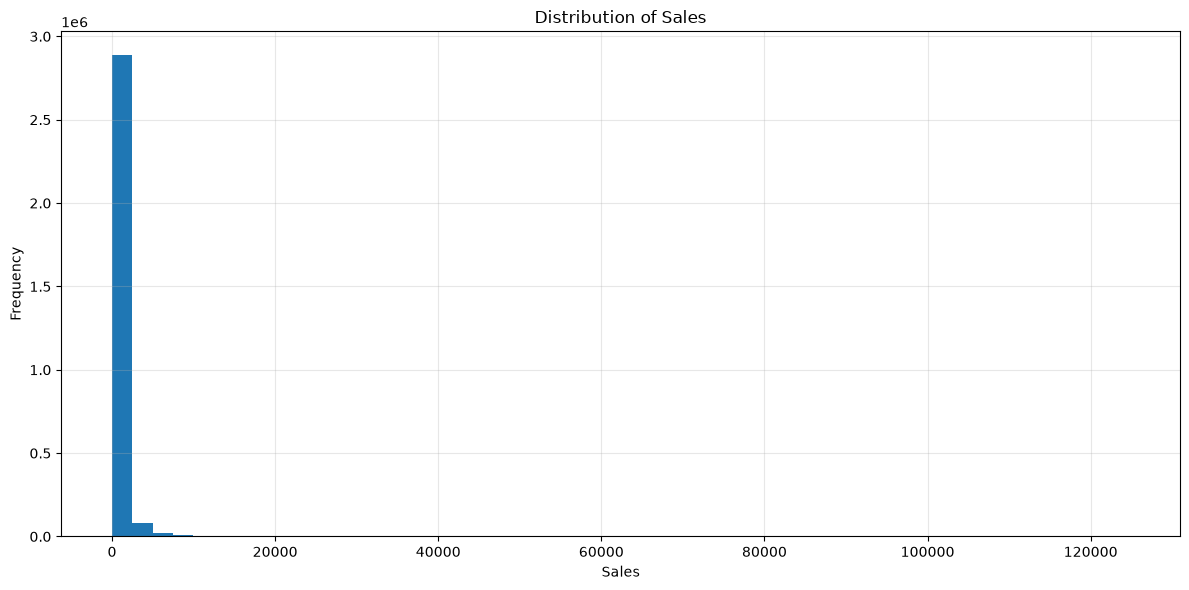

In [21]:
plt.figure(figsize=(12, 6))

plt.hist(
    df["sales"],
    bins=50
)

plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "sales_distribution.png")
plt.show()

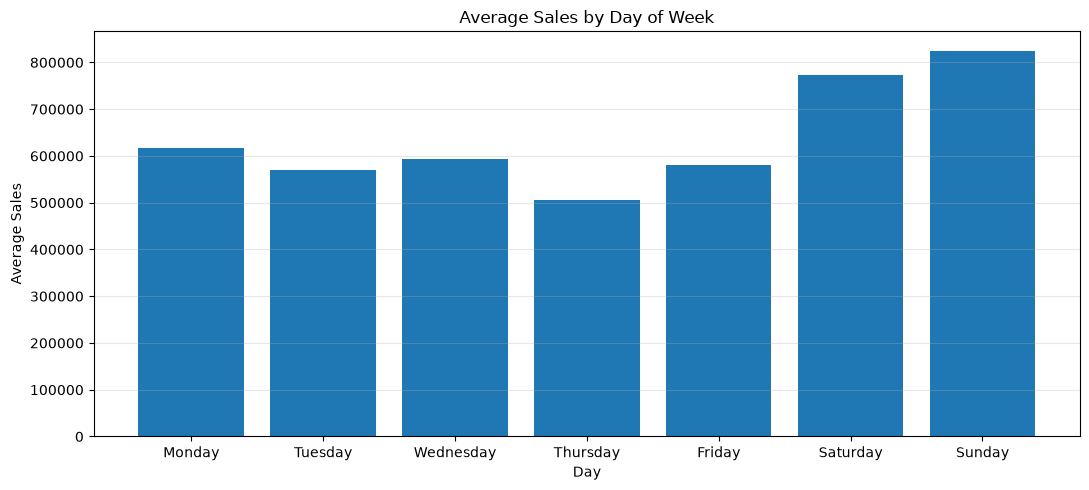

In [22]:
daily_sales["day_of_week"] = (
    daily_sales["date"].dt.dayofweek
)

weekday_sales = (
    daily_sales.groupby("day_of_week")["total_sales"]
    .mean()
)

days = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

plt.figure(figsize=(11, 5))

plt.bar(days, weekday_sales.values)

plt.title("Average Sales by Day of Week")
plt.xlabel("Day")
plt.ylabel("Average Sales")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "weekly_sales.png")
plt.show()

In [23]:
# Create a clean time series
sales_series = (
    daily_sales.set_index("date")["total_sales"]
    .sort_index()
    .asfreq("D")
)

# Check for missing dates
print("Missing daily observations:", sales_series.isna().sum())

# Fill missing dates with zero only if there are genuinely
# missing calendar observations in the source data.
sales_series = sales_series.fillna(0)

Missing daily observations: 4


In [24]:
def create_features(series):

    features = pd.DataFrame(index=series.index)

    # Calendar features
    features["year"] = series.index.year
    features["month"] = series.index.month
    features["day"] = series.index.day
    features["day_of_week"] = series.index.dayofweek
    features["day_of_year"] = series.index.dayofyear
    features["week_of_year"] = (
        series.index.isocalendar().week.astype(int).to_numpy()
    )

    features["is_weekend"] = (
        series.index.dayofweek >= 5
    ).astype(int)

    # Lag features
    features["lag_1"] = series.shift(1)
    features["lag_7"] = series.shift(7)
    features["lag_14"] = series.shift(14)
    features["lag_28"] = series.shift(28)

    # Rolling averages
    features["rolling_mean_7"] = (
        series.shift(1).rolling(7).mean()
    )

    features["rolling_mean_14"] = (
        series.shift(1).rolling(14).mean()
    )

    features["rolling_mean_28"] = (
        series.shift(1).rolling(28).mean()
    )

    return features

In [25]:
features = create_features(sales_series)

model_data = features.copy()

model_data["target"] = sales_series

# Remove rows without sufficient historical information
model_data = model_data.dropna()

X = model_data.drop(columns=["target"])
y = model_data["target"]

print("Feature dataset shape:", X.shape)

display(model_data.head())

Feature dataset shape: (1660, 14)


,year,month,day,day_of_week,day_of_year,week_of_year,is_weekend,lag_1,lag_7,lag_14,lag_28,rolling_mean_7,rolling_mean_14,rolling_mean_28,target
date,,,,,,,,,,,,,,,
2013-01-29,2013,1,29,1,29,5,0,285460.169953,296214.728983,299129.549954,2511.618999,320916.224872,330877.422002,339672.163349,264488.818076
2013-01-30,2013,1,30,2,30,5,0,264488.818076,283258.453032,318347.913946,496092.417944,316383.951885,328403.084010,349028.491888,281061.127052
2013-01-31,2013,1,31,3,31,5,0,281061.127052,247245.690995,267498.515975,361461.231124,316070.048174,325739.742089,341348.802928,271254.217996
2013-02-01,2013,2,1,4,32,5,0,271254.217996,290022.771930,296130.850028,354459.677093,319499.837745,326008.006519,338127.123887,369402.055266
2013-02-02,2013,2,2,5,33,5,1,369402.055266,413799.767975,432459.852021,477350.121229,330839.735365,331241.664036,338660.780251,518887.462705


In [26]:
VALIDATION_DAYS = 16

validation_start = (
    sales_series.index.max()
    - pd.Timedelta(days=VALIDATION_DAYS - 1)
)

train_mask = X.index < validation_start

X_train = X.loc[train_mask]
y_train = y.loc[train_mask]

print("Training observations:", len(X_train))
print("Validation start:", validation_start)
print("Validation end:", sales_series.index.max())

Training observations: 1644
Validation start: 2017-07-31 00:00:00
Validation end: 2017-08-15 00:00:00


In [27]:
def seasonal_naive_forecast(history, forecast_dates):

    history = history.copy()
    predictions = []

    for date in forecast_dates:

        previous_week = date - pd.Timedelta(days=7)

        prediction = history.loc[previous_week]

        predictions.append(prediction)

        history.loc[date] = prediction

    return np.array(predictions)

In [28]:
rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=18,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [29]:
def make_future_features(date, history):

    previous_date = date - pd.Timedelta(days=1)

    row = {
        "year": date.year,
        "month": date.month,
        "day": date.day,
        "day_of_week": date.dayofweek,
        "day_of_year": date.dayofyear,
        "week_of_year": date.isocalendar().week,
        "is_weekend": int(date.dayofweek >= 5),

        "lag_1": history.loc[
            date - pd.Timedelta(days=1)
        ],

        "lag_7": history.loc[
            date - pd.Timedelta(days=7)
        ],

        "lag_14": history.loc[
            date - pd.Timedelta(days=14)
        ],

        "lag_28": history.loc[
            date - pd.Timedelta(days=28)
        ],

        "rolling_mean_7": history.loc[:previous_date].tail(7).mean(),

        "rolling_mean_14": history.loc[:previous_date].tail(14).mean(),

        "rolling_mean_28": history.loc[:previous_date].tail(28).mean()
    }

    return pd.DataFrame([row])

In [30]:
def recursive_forecast(model, history, forecast_dates):

    history = history.copy()

    predictions = []

    for date in forecast_dates:

        future_features = make_future_features(
            date,
            history
        )

        prediction = model.predict(
            future_features
        )[0]

        prediction = max(0, prediction)

        predictions.append(prediction)

        history.loc[date] = prediction

    return np.array(predictions)

In [31]:
validation_dates = sales_series.loc[
    validation_start:
].index

history = sales_series.loc[
    sales_series.index < validation_start
]

actual_values = sales_series.loc[
    validation_dates
].values

# Random Forest predictions
rf_predictions = recursive_forecast(
    rf_model,
    history,
    validation_dates
)

# Baseline predictions
baseline_predictions = seasonal_naive_forecast(
    history,
    validation_dates
)

print("Validation predictions generated!")

Validation predictions generated!


In [32]:
def evaluate_model(actual, predicted):

    mae = mean_absolute_error(
        actual,
        predicted
    )

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    rmsle = np.sqrt(
        mean_squared_log_error(
            np.maximum(actual, 0),
            np.maximum(predicted, 0)
        )
    )

    return {
        "MAE": mae,
        "RMSE": rmse,
        "RMSLE": rmsle
    }

In [33]:
baseline_metrics = evaluate_model(
    actual_values,
    baseline_predictions
)

rf_metrics = evaluate_model(
    actual_values,
    rf_predictions
)

comparison = pd.DataFrame(
    [baseline_metrics, rf_metrics],
    index=["Seasonal Naive", "Random Forest"]
)

display(comparison)

,MAE,RMSE,RMSLE
Seasonal Naive,89634.530001,131195.331597,0.147868
Random Forest,81975.417236,103663.744491,0.111419


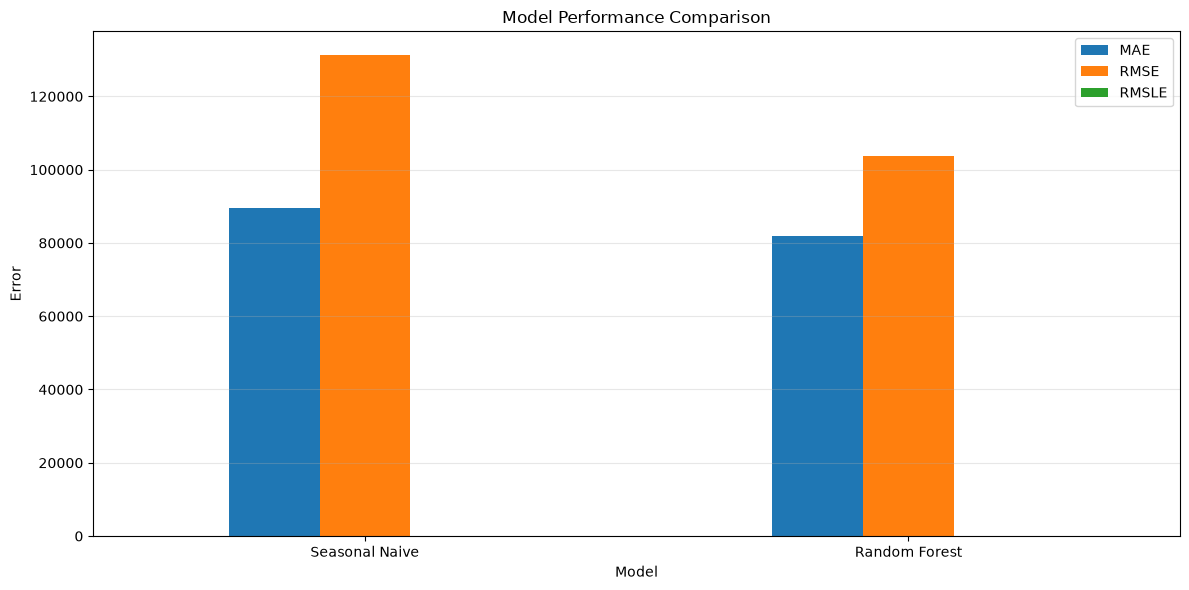

In [34]:
comparison.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Error")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "model_comparison.png")
plt.show()

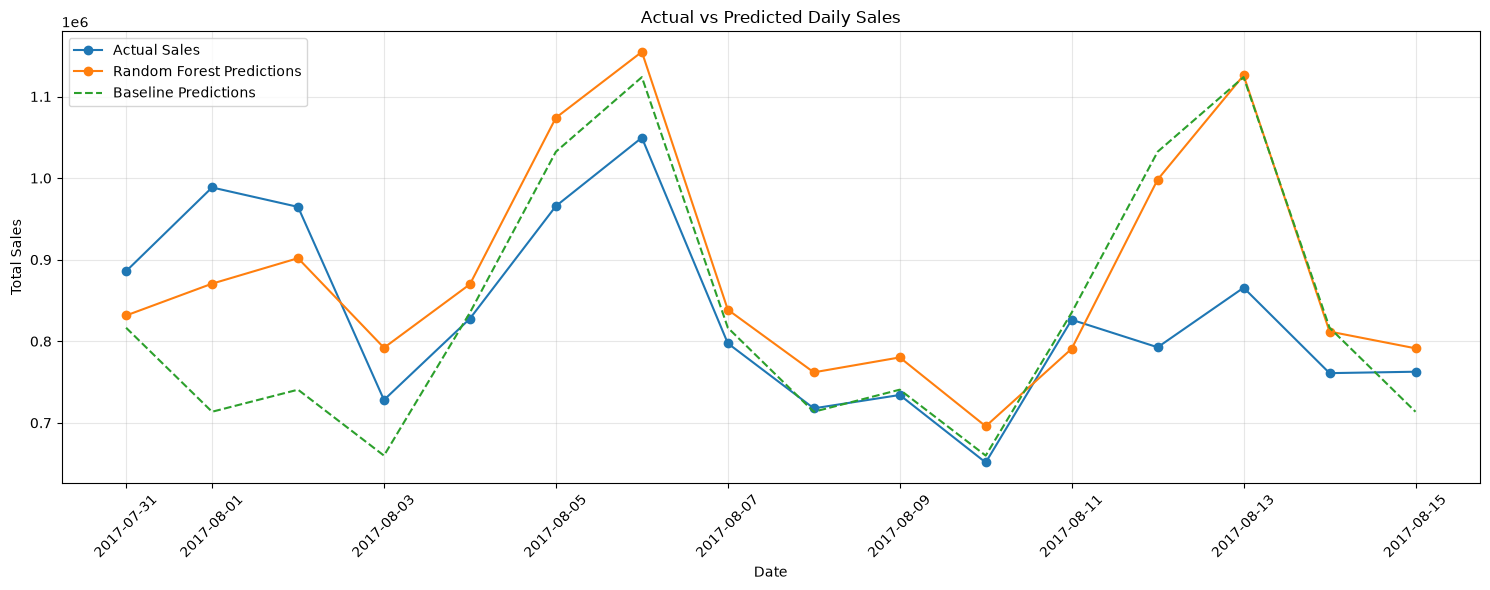

In [35]:
plt.figure(figsize=(15, 6))

plt.plot(
    validation_dates,
    actual_values,
    label="Actual Sales",
    marker="o"
)

plt.plot(
    validation_dates,
    rf_predictions,
    label="Random Forest Predictions",
    marker="o"
)

plt.plot(
    validation_dates,
    baseline_predictions,
    label="Baseline Predictions",
    linestyle="--"
)

plt.title("Actual vs Predicted Daily Sales")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "validation_forecast.png")
plt.show()

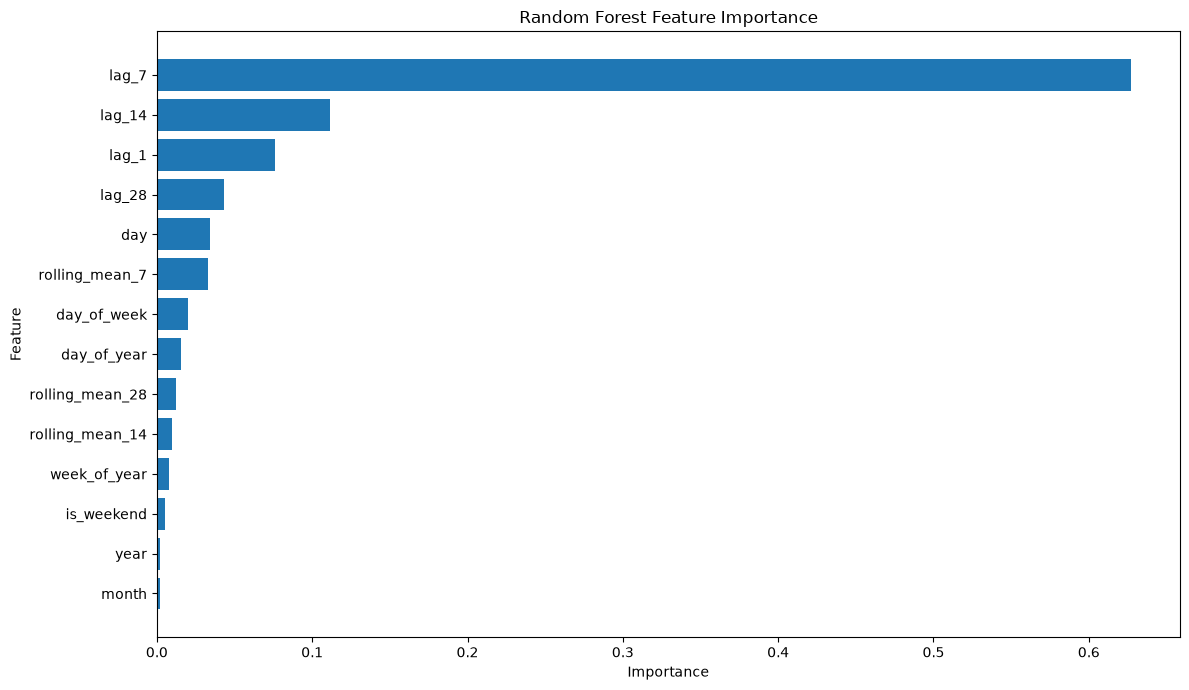

,Feature,Importance
8,lag_7,0.627339
9,lag_14,0.111753
7,lag_1,0.075842
10,lag_28,0.042972
2,day,0.034371
11,rolling_mean_7,0.032911
3,day_of_week,0.020305
4,day_of_year,0.015634
13,rolling_mean_28,0.012133
12,rolling_mean_14,0.009724


In [36]:
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

plt.figure(figsize=(12, 7))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "feature_importance.png")
plt.show()

display(importance)

In [37]:
final_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=18,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)

final_model.fit(X, y)

print("Final model trained successfully!")

Final model trained successfully!


In [38]:
test = pd.read_csv(
    data_path / "test.csv",
    parse_dates=["date"]
)

future_dates = pd.DatetimeIndex(
    sorted(test["date"].unique())
)

print("Forecast start:", future_dates.min())
print("Forecast end:", future_dates.max())
print("Forecast horizon:", len(future_dates), "days")

Forecast start: 2017-08-16 00:00:00
Forecast end: 2017-08-31 00:00:00
Forecast horizon: 16 days


In [39]:
future_predictions = recursive_forecast(
    final_model,
    sales_series,
    future_dates
)

forecast_df = pd.DataFrame({
    "date": future_dates,
    "predicted_sales": future_predictions
})

display(forecast_df)

,date,predicted_sales
0,2017-08-16,7.521076e+05
1,2017-08-17,6.814292e+05
2,2017-08-18,7.828870e+05
3,2017-08-19,9.003414e+05
4,2017-08-20,9.784771e+05
5,2017-08-21,7.714420e+05
6,2017-08-22,7.269100e+05
7,2017-08-23,7.379177e+05
8,2017-08-24,6.586228e+05
9,2017-08-25,8.022975e+05


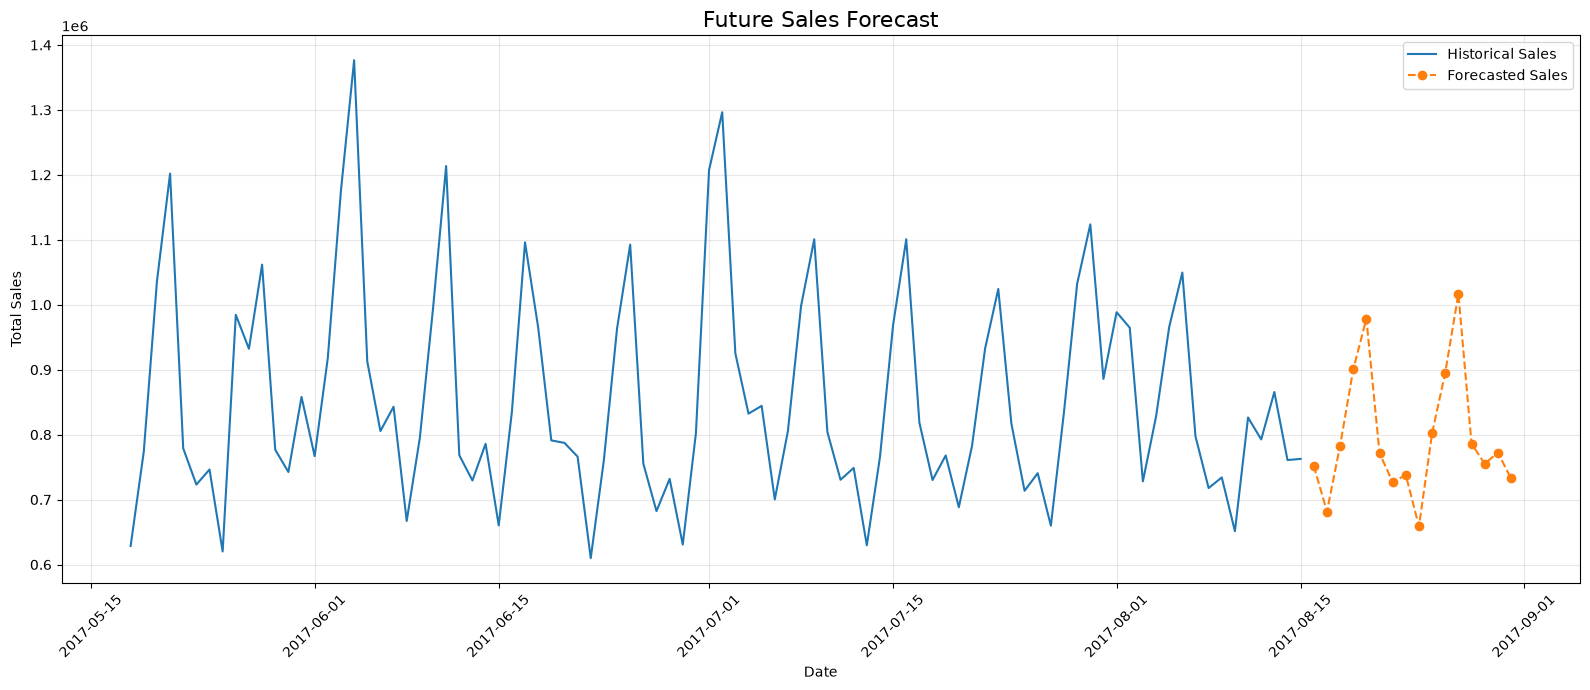

In [40]:
plt.figure(figsize=(16, 7))

# Historical sales
plt.plot(
    sales_series.index[-90:],
    sales_series.values[-90:],
    label="Historical Sales"
)

# Future predictions
plt.plot(
    future_dates,
    future_predictions,
    label="Forecasted Sales",
    marker="o",
    linestyle="--"
)

plt.title("Future Sales Forecast", fontsize=16)
plt.xlabel("Date")
plt.ylabel("Total Sales")

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "future_sales_forecast.png")
plt.show()

In [41]:
total_forecast = forecast_df["predicted_sales"].sum()

average_forecast = forecast_df["predicted_sales"].mean()

highest_day = forecast_df.loc[
    forecast_df["predicted_sales"].idxmax()
]

lowest_day = forecast_df.loc[
    forecast_df["predicted_sales"].idxmin()
]

print("=" * 55)
print("SALES FORECAST BUSINESS REPORT")
print("=" * 55)

print(f"Forecast period: {len(forecast_df)} days")

print(f"Expected total sales: {total_forecast:,.2f}")

print(f"Average daily sales: {average_forecast:,.2f}")

print(
    f"Highest forecast: {highest_day['predicted_sales']:,.2f}"
)

print(
    f"Highest sales date: {highest_day['date'].date()}"
)

print(
    f"Lowest forecast: {lowest_day['predicted_sales']:,.2f}"
)

print(
    f"Lowest sales date: {lowest_day['date'].date()}"
)

print("=" * 55)

SALES FORECAST BUSINESS REPORT
Forecast period: 16 days
Expected total sales: 12,751,616.58
Average daily sales: 796,976.04
Highest forecast: 1,017,005.74
Highest sales date: 2017-08-27
Lowest forecast: 658,622.82
Lowest sales date: 2017-08-24


In [42]:
# Save trained model
joblib.dump(
    final_model,
    MODEL_DIR / "sales_forecasting_model.pkl"
)

# Save forecast results
forecast_df.to_csv(
    BASE_DIR / "forecast_results.csv",
    index=False
)

# Save validation results
validation_results = pd.DataFrame({
    "date": validation_dates,
    "actual_sales": actual_values,
    "random_forest_predictions": rf_predictions,
    "baseline_predictions": baseline_predictions
})

validation_results.to_csv(
    BASE_DIR / "validation_results.csv",
    index=False
)

# Save evaluation metrics
comparison.to_csv(
    BASE_DIR / "model_evaluation.csv"
)

print("Project results saved successfully!")

Project results saved successfully!
